# Access the analysis ready CAMS Europe air quality forecasts data

This notebook provides an example of how to open the cams-europe-air-quality-forecasts Zarr store using xarray.
You will need to insert your CDS API key where indicated in the following code cell (available on [your profile page](https://ads.atmosphere.copernicus.eu/profile)).
For more information on using the Data Store Analysis Ready Datasets, please see the [user documentation pages](https://cds.climate.copernicus.eu/datasets/how-to-use-the-dss-arco-dataset).

In [12]:
import os
cdsapi_key = "<INSERT-CDS-API-KEY-HERE>"

# The following attempts to find the CDS API key in your environment.
if cdsapi_key == "<INSERT-CDS-API-KEY-HERE>":
    cdsapi_key = None
if cdsapi_key is None:
    cdsapi_key = os.getenv("CDSAPI_KEY")
if cdsapi_key is None and os.path.exists(os.path.expanduser("~/.cdsapirc")):
    with open(os.path.expanduser("~/.cdsapirc"), "r") as f:
        for line in f:
            if line.startswith("key:"):
                cdsapi_key = line.split(":")[1].strip()
                break
if cdsapi_key is None:
    raise ValueError("CDS API key not found. Please set the CDSAPI_KEY environment variable or create a ~/.cdsapirc file.")

## Plug and play access

The code below provides a simple plug and play example of how to use the Zarr Store for light-weight access.

In [16]:
import xarray as xr

# Geo-chunked all forecast data (optimised for time-series at a single location)
geochunked_ens_sfc_url = "https://arco.datastores.ecmwf.int/cadl-arco-geo-001/arco/cams_europe_air_quality_forecasts/ens-sfc-multiforecast/geoChunked.zarr"

# Time-chunked all forecast data (optimised for map at a single time step)
timechunked_ens_sfc_url = "https://arco.datastores.ecmwf.int/cadl-arco-time-001/arco/cams_europe_air_quality_forecasts/ens-sfc-multiforecast/timeChunked.zarr"

# Open the zarr store with xarray, users must insert their API key where indicated.
ds = xr.open_zarr(
    geochunked_ens_sfc_url,
    consolidated=True,
     storage_options = {
        "headers": {"Authorization": f"Bearer {cdsapi_key}"}
    }
)
 
# Inspect the variables
print(ds)

<xarray.Dataset> Size: 166GB
Dimensions:     (time: 210, time_step: 96, elevation: 1, latitude: 420,
                 longitude: 700)
Coordinates:
  * time        (time) datetime64[ns] 2kB 2026-04-14 2026-04-15 ... 2026-11-09
  * time_step   (time_step) int16 192B 0 1 2 3 4 5 6 7 ... 89 90 91 92 93 94 95
  * elevation   (elevation) float32 4B 0.0
  * latitude    (latitude) float32 2kB 30.05 30.15 30.25 ... 71.75 71.85 71.95
  * longitude   (longitude) float32 3kB -24.95 -24.85 -24.75 ... 44.85 44.95
Data variables:
    co_conc     (time, time_step, elevation, latitude, longitude) float32 24GB dask.array<chunksize=(64, 96, 1, 16, 8), meta=np.ndarray>
    dust        (time, time_step, elevation, latitude, longitude) float32 24GB dask.array<chunksize=(64, 96, 1, 16, 8), meta=np.ndarray>
    no2_conc    (time, time_step, elevation, latitude, longitude) float32 24GB dask.array<chunksize=(64, 96, 1, 16, 8), meta=np.ndarray>
    o3_conc     (time, time_step, elevation, latitude, longitude) fl

Extract a point and plot a time-series using earthkit-plots.

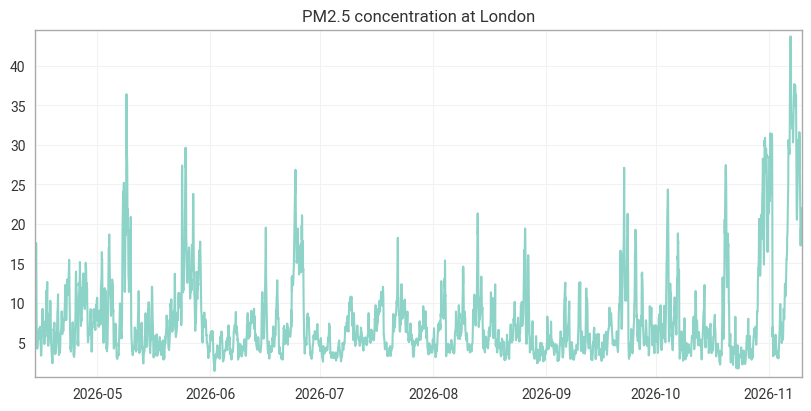

In [18]:
from earthkit import plots as ekp


import pandas as pd
import xarray as xr

def unravel_forecast(
    ds: xr.Dataset,
    step_range: tuple[int, int] = (0, 23),
    keep: str | None = None,
) -> xr.Dataset:
    """
    Convert a (time, time_step) forecast dataset to a single valid_time dimension.

    Parameters
    ----------
    ds : xr.Dataset
        Dataset with dims `time` (forecast base time) and `time_step` (lead time, hours).
    step_range : (int, int)
        Inclusive range of lead hours to keep, e.g. (0, 23).
    keep : {None, "first", "last"}
        How to handle duplicate valid times, which occur when the step range spans
        more than the spacing between base times (here 24 h). None keeps all of them,
        "last" keeps the value from the most recent forecast, "first" the oldest.
    """
    start, stop = step_range

    sub = ds.sel(time_step=slice(start, stop))
    stacked = sub.stack(valid_time=("time", "time_step"), create_index=False)
    lead = pd.to_timedelta(stacked.time_step.values, unit="h")
    valid = pd.DatetimeIndex(stacked.time.values) + lead

    stacked = stacked.assign_coords(valid_time=("valid_time", valid))

    stacked = stacked.sortby("valid_time")

    if keep is not None:
        stacked = stacked.drop_duplicates("valid_time", keep=keep)

    # Rename the carried-over coords for clarity
    return stacked.rename({"time": "base_time", "time_step": "lead_hours"})

# Select variable to plot
variable_name = "pm2p5_conc"

ds_valid = unravel_forecast(ds, step_range=(0, 23))

plot_data = ds_valid[variable_name].sel(
    latitude=51.5, longitude=-0.1, method="nearest"
)

chart = ekp.TimeSeries()

chart.line(plot_data)

chart.title("PM2.5 concentration at London")
chart.legend()

chart.show()

## Advanced usage

If your workflow requires access to larger amounts of data, it is recommended that you include a retry mechanism.
This is not provided in the current default zarr engine for xarray, instead we can define a custom "`store`" which is
used when connecting to the remote zarr data.

In [19]:
!pip install -q obstore
import xarray as xr
from obstore.store import HTTPStore
from zarr.storage import ObjectStore

# Geo-chunked all forecast data (optimised for time-series at a single location)
geochunked_ens_sfc_url = "https://arco.datastores.ecmwf.int/cadl-arco-geo-001/arco/cams_europe_air_quality_forecasts/ens-sfc-multiforecast/geoChunked.zarr"

# Time-chunked all forecast data (optimised for map at a single time step)
timechunked_ens_sfc_url = "https://arco.datastores.ecmwf.int/cadl-arco-time-001/arco/cams_europe_air_quality_forecasts/ens-sfc-multiforecast/timeChunked.zarr"


# Use obstore's HTTPStore to create a store with retry configuration,
# and then wrap it in a zarr ObjectStore to read with xarray.
# See https://github.com/developmentseed/obstore/blob/main/obstore/python/obstore/_store/_retry.pyi
# for more details on the retry configuration options.
http_store = HTTPStore(
    geochunked_ens_sfc_url,
    client_options={
        "default_headers": {"Authorization": f"Bearer {cdsapi_key}"},
    },
)
store = ObjectStore(http_store, read_only=True)
ds = xr.open_zarr(store)
ds

<xarray.Dataset> Size: 166GB
Dimensions:     (time: 210, time_step: 96, elevation: 1, latitude: 420,
                 longitude: 700)
Coordinates:
  * time        (time) datetime64[ns] 2kB 2026-04-14 2026-04-15 ... 2026-11-09
  * time_step   (time_step) int16 192B 0 1 2 3 4 5 6 7 ... 89 90 91 92 93 94 95
  * elevation   (elevation) float32 4B 0.0
  * latitude    (latitude) float32 2kB 30.05 30.15 30.25 ... 71.75 71.85 71.95
  * longitude   (longitude) float32 3kB -24.95 -24.85 -24.75 ... 44.85 44.95
Data variables:
    co_conc     (time, time_step, elevation, latitude, longitude) float32 24GB dask.array<chunksize=(64, 96, 1, 16, 8), meta=np.ndarray>
    dust        (time, time_step, elevation, latitude, longitude) float32 24GB dask.array<chunksize=(64, 96, 1, 16, 8), meta=np.ndarray>
    no2_conc    (time, time_step, elevation, latitude, longitude) float32 24GB dask.array<chunksize=(64, 96, 1, 16, 8), meta=np.ndarray>
    o3_conc     (time, time_step, elevation, latitude, longitude) float32 24GB dask.array<chunksize=(64, 96, 1, 16, 8), meta=np.ndarray>
    pm10_conc   (time, time_step, elevation, latitude, longitude) float32 24GB dask.array<chunksize=(64, 96, 1, 16, 8), meta=np.ndarray>
    pm2p5_conc  (time, time_step, elevation, latitude, longitude) float32 24GB dask.array<chunksize=(64, 96, 1, 16, 8), meta=np.ndarray>
    so2_conc    (time, time_step, elevation, latitude, longitude) float32 24GB dask.array<chunksize=(64, 96, 1, 16, 8), meta=np.ndarray>
Attributes:
    FORECAST:     Europe, 20260416+[0H_95H]
    history:      Model ENSEMBLE FORECAST
    institution:  Data produced by Meteo France
    project:      MACC-RAQ (http://macc-raq.gmes-atmosphere.eu)
    source:       Data from ENSEMBLE model
    summary:      ENSEMBLE model hourly FORECAST of SO2 concentration at the ...
    title:        SO2 Air Pollutant FORECAST at the Surface

The result is the same as the previous example, this just provides a more robust connection, preventing your
workflow crashing due to temporary network issues.